# Notebook 2: ladders, the gap certificate, and batch insertion

This notebook replicates Section 3 (the inductive step), the insertion steps of Section 4.2, the results of Sections 5.1, 5.2, and 5.4, and the checks of Appendix A of *Topology Persistence under Target Insertion in Ramified Optimal Transport*. It rebuilds Tables 1, 2, 4, and 5 and Figures 4 and 5 from the results stored in `figures/` and compares every table with the file in `overleaf_A/tables`. The rows of the application (the vaccine network) are left to notebook 3; notebook 1 covers the theory of Section 2 and the exact solver.

**How to run.** Open the notebook in Google Colab and choose *Runtime > Run all*; there is nothing to upload, mount, or find. The first code cell unpacks the code and data embedded in the notebook (36 files, 2 MB: the library `rot_core.py`, `rot_tools.py`, and `plotstyle.py` in `colab/`, the benchmark instances in `data/benchmarks` with their data dictionary `data/DATA_DICTIONARY.md`, the stored results and reference figures in `figures/`, and the tables in `overleaf_A/tables`) into the folder `/content/ArticleA` and makes it the working directory; every path named below, such as `figures/`, `overleaf_A/tables`, or `colab/output/`, is inside that folder. Outside Colab, in Jupyter or VS Code, the same cell writes the folder `ArticleA_runtime` next to the notebook. No GPU and no paid service are needed.

**Default run and full run.** The studies of the paper took hours on a 24-core laptop, so by default every long loop runs a documented subset, compares each recomputed number with the stored one, and prints `PASS` or `FAIL`; the tables, the figures, and the numbers quoted in the text come from the stored results. The loops run in parallel processes, at most six (`RT.MAX_WORKERS`, or the environment variable `ROT_MAX_WORKERS`). The default run took about one and a half minutes on the laptop used for the paper with six processes and under three with two; a free Colab session, with two slower cores, takes a few minutes more. Setting `RUN_FULL = True` reruns the complete studies (hours on a laptop, days on Colab):

| Section | Default subset | `RUN_FULL = True` |
|---|---|---|
| 2, Lemma 3.2 | the first 48 of the 272 random instances | all 272 |
| 3, Theorem 3.3 | the 24 rungs from three and four targets of the deterministic ladders | all 42 rungs |
| 4, accuracy of the solver | the 17 instances with five terminals | all 27 instances |
| 4, Proposition 3.4 and Corollary 3.6 | 8 of the 90 certified rungs | all 90 |
| 5, replicated ladders | one ladder per family ($\alpha=0.75$, seed 0) up to five targets | all 240 ladders up to six targets |
| 6, deterministic ladders | two ladders up to five targets | all 12 ladders |
| 7, reach of the program | $k=4,5$ terminals and $b=1,2$ new targets | $k=4,5,6$ and $b=1,2,3$ |
| 7, batch insertion | the step from three to five targets, $\omega=0,1$ | the whole ladders with $\omega=0,1,2$ |
| 7, restriction and cherries | the two steps from three to five targets; 6 of the 96 joint misses | all steps; all 96 |
| 8, eight-terminal references | stored values | every topology polished (about 20 minutes per case) |

## 0. Setup

In [1]:
# @title Unpack the code and data embedded in this notebook
# Nothing has to be uploaded, mounted, or found. PAYLOAD, at the end of this cell, is a zip archive in base64 of the
# files this notebook reads and of the data dictionary that its text names, with their paths in the folder ArticleA
# of the paper. The cell writes them to a working folder, /content/ArticleA in Google Colab and ArticleA_runtime next
# to the notebook elsewhere, puts that folder and its subfolders colab/ and code/ on sys.path, makes it the working
# directory, and lists what it wrote.
import base64, importlib.util, io, os, sys, zipfile


def running_in_colab():
    """True in Google Colab, where the folder /content exists and the module google.colab is available."""
    if not os.path.isdir("/content"):
        return False
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        return False


def same_content(path, data):
    """True when the file at path exists and holds exactly data."""
    if not os.path.isfile(path) or os.path.getsize(path) != len(data):
        return False
    with open(path, "rb") as f:
        return f.read() == data


def unpack(payload):
    """Extract the embedded archive into the working folder and enter it; returns the folder and whether it is Colab."""
    in_colab = running_in_colab()
    if in_colab:
        root = "/content/ArticleA"
    else:
        here = os.getcwd()                  # Jupyter and VS Code start the kernel in the folder of the notebook
        root = here if os.path.basename(here) == "ArticleA_runtime" else os.path.join(here, "ArticleA_runtime")
    listing = []
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(payload))) as z:
        for info in z.infolist():
            parts = info.filename.split("/")
            if info.is_dir() or info.filename.startswith("/") or ".." in parts:
                continue
            data = z.read(info)             # checks the CRC of the entry
            target = os.path.join(root, *parts)
            os.makedirs(os.path.dirname(target), exist_ok=True)
            if not same_content(target, data):
                with open(target + ".part", "wb") as f:      # a whole file or none, also when two notebooks
                    f.write(data)                            # unpack into the same folder at the same time
                os.replace(target + ".part", target)
            listing.append((info.filename, len(data)))
    for sub in ("", "code", "colab"):       # in the end colab/ comes first on sys.path, then code/, then the folder
        folder = os.path.join(root, sub) if sub else root
        if os.path.isdir(folder) and folder not in sys.path:
            sys.path.insert(0, folder)
    os.chdir(root)
    where = root if in_colab else "ArticleA_runtime, next to this notebook"
    print(f"unpacked {len(listing)} files, {sum(n for _, n in listing) / 1e6:.1f} MB, into {where}:")
    for folder in sorted({os.path.dirname(name) for name, _ in listing}):
        names = [os.path.basename(name) for name, _ in listing if os.path.dirname(name) == folder]
        print(f"  {folder}/: {', '.join(names)}")
    return root, in_colab

PAYLOAD = """
...
"""
ROOT, IN_COLAB = unpack(PAYLOAD)

unpacked 36 files, 2.0 MB, into /content/ArticleA:
  colab/: plotstyle.py, rot_core.py, rot_tools.py
  data/: DATA_DICTIONARY.md
  data/benchmarks/: instances.csv, targets.csv
  figures/: dual_bound_check.json
  figures/inductive/: certificate_ladder.json, check_saving_lemma.json, fig_inductive_ladder.png, inductive_ladder.json, inductive_ladder_hard.json, restriction_check_v2.json
  figures/inductive/cement-a050/: summary.csv
  figures/inductive/cement-a050-w1/: summary.csv
  figures/inductive/cement-a075/: summary.csv
  figures/inductive/cement-a075-w1/: summary.csv
  figures/inductive/cement-a085/: summary.csv
  figures/inductive/cement-a085-aer/: summary.csv
  figures/inductive/cement-a085-w1/: summary.csv
  figures/inductive/clusters-a075/: summary.csv
  figures/inductive/clusters-a075-w1/: summary.csv
  figures/inductive/clusters-a075-w2/: summary.csv
  figures/inductive/disk-unequal-a050/: summary.csv
  figures/inductive/disk-unequal-a050-w1/: summary.csv
  figures/inductive/dis

In [2]:
# Setup: the same cell works in Google Colab and locally. ROOT is the working folder written by the cell above.
import os, sys, importlib.util, subprocess
for var in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(var, "1")            # one BLAS thread per process; the long loops use processes instead

if IN_COLAB:
    # Latin Modern gives the figures the face of the manuscript; without it they use matplotlib's Computer Modern
    subprocess.run("apt-get -qq install fonts-lmodern > /dev/null 2>&1", shell=True)

# pip installs only what is missing (Colab already has all of these)
missing = [p for p in ("numpy", "scipy", "matplotlib", "pandas", "sympy") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

COLAB_DIR = os.path.join(ROOT, "colab")       # rot_core.py, rot_tools.py, plotstyle.py
FIG = os.path.join(ROOT, "figures")            # stored results of the paper
TABLES = os.path.join(ROOT, "overleaf_A", "tables")
OUT = os.path.join(COLAB_DIR, "output")        # everything this notebook writes
for sub in ("figures", "tables", "results"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
print("folder", os.path.basename(ROOT), "| Colab" if IN_COLAB else "| local", "| cores:", os.cpu_count())

folder ArticleA | Colab | cores: 2


In [3]:
RUN_FULL = False      # True reruns every study in full (see the table above)

import filecmp, json, time
import numpy as np
from IPython.display import Image, display
import rot_core as RC       # geometry of a fixed topology, enumeration of full topologies, exact solver
import rot_tools as RT      # instances, restriction, insertion steps, certificate, tables, figures
ck = RT.Checker()           # collects the PASS/FAIL lines of this notebook
T_START = time.perf_counter()

def load(*parts):
    """A stored result of the paper."""
    return json.load(open(os.path.join(FIG, *parts)))

REP_ROWS = load("replication", "ladder_replication.json")     # 240 random ladders, one row per number of targets
LADDER = load("inductive", "inductive_ladder.json")            # deterministic ladders on the disk, unit masses
HARD = load("inductive", "inductive_ladder_hard.json")         # unequal masses and two clusters
DET = RT.deterministic_instances()                             # the four deterministic instances
CERT = [r for r in load("inductive", "certificate_ladder.json") if r["instance"] in DET]
RIG = load("replication", "certificate_rigorous.json")         # the 90 rungs checked with lower bounds
print(len(REP_ROWS), "rows of replicated ladders;", len(CERT), "rungs of deterministic ladders;", len(RIG), "rigorous rungs")

960 rows of replicated ladders; 42 rungs of deterministic ladders; 90 rigorous rungs


### The benchmark instances

The instances of Sections 5.1, 5.2, and 5.4 come from fixed seeds: `RT.make_instance(family, seed)` gives the 80 random point sets of the replicated ladders (four families, seeds 0 to 19, six targets), and `RT.disk_points`, `RT.instance_disk_unequal`, and `RT.instance_two_clusters` give the deterministic ladders. The same instances were written to `data/benchmarks`, one row per instance in `instances.csv` and one row per target in `targets.csv` (columns in `data/DATA_DICTIONARY.md`), so that they can be used without the code; they were written by `make_benchmark_instances.py`, a script of the paper's code that calls the generators of the original study scripts and that this notebook does not need. The cell below reads the two files and checks that they hold, bit for bit, the instances produced by the generators of this notebook.

In [4]:
import csv
BENCH_DIR = os.path.join(ROOT, "data", "benchmarks")
with open(os.path.join(BENCH_DIR, "instances.csv"), newline="", encoding="utf-8") as f:
    bench_rows = list(csv.DictReader(f))
with open(os.path.join(BENCH_DIR, "targets.csv"), newline="", encoding="utf-8") as f:
    bench_targets = list(csv.DictReader(f))
BENCH = {}                                  # identifier -> (source, targets in the order of insertion, masses)
for r in bench_rows:
    rows = [t for t in bench_targets if t["instance"] == r["instance"]]
    BENCH[r["instance"]] = (np.array([float(r["source_x"]), float(r["source_y"])]),
                            np.array([[float(t["x"]), float(t["y"])] for t in rows]),
                            np.array([float(t["mass"]) for t in rows]))
print(len(bench_rows), "instances,", len(bench_targets), "targets;",
      sum(r["set"] == "replicated" for r in bench_rows), "replicated and", sum(r["set"] == "ladder" for r in bench_rows), "ladders")

same = lambda a, b: all(np.array_equal(x, y) for x, y in zip(a, b))
ck("data/benchmarks: the 80 replicated instances equal RT.make_instance(family, seed), seeds 0 to 19 (bit for bit)",
   all(same(RT.make_instance(fam, seed), BENCH[f"{fam}/s{seed:02d}"]) for fam in RT.FAMILIES for seed in range(20)))
T7 = RT.disk_points(7)
LADDER_ID = {"Disk, center": "ladder/disk-center", "Disk, offset 0.5": "ladder/disk-offset",
             "Disk, unequal masses": "ladder/disk-unequal", "Two clusters": "ladder/two-clusters"}
ck("data/benchmarks: the four deterministic ladders equal RT.disk_points(7), RT.instance_disk_unequal(8), and "
   "RT.instance_two_clusters(8), and the instances of Tables 2 and 5 are their prefixes (bit for bit)",
   same((np.zeros(2), T7, np.ones(7)), BENCH["ladder/disk-center"])
   and same((np.array([0.5, 0.0]), T7, np.ones(7)), BENCH["ladder/disk-offset"])
   and same(RT.instance_disk_unequal(8), BENCH["ladder/disk-unequal"])
   and same(RT.instance_two_clusters(8), BENCH["ladder/two-clusters"])
   and all(same((s0, T0, m0), (BENCH[LADDER_ID[k]][0], BENCH[LADDER_ID[k]][1][:n], BENCH[LADDER_ID[k]][2][:n]))
           for k, (s0, T0, m0, n) in DET.items()))

84 instances, 510 targets; 80 replicated and 4 ladders
PASS  data/benchmarks: the 80 replicated instances equal RT.make_instance(family, seed), seeds 0 to 19 (bit for bit)
PASS  data/benchmarks: the four deterministic ladders equal RT.disk_points(7), RT.instance_disk_unequal(8), and RT.instance_two_clusters(8), and the instances of Tables 2 and 5 are their prefixes (bit for bit)


## 1. Restriction and extension (Definition 3.1)

Throughout, $0\le\alpha<1$, $S_n=\lbrace y_1,\dots,y_n\rbrace $ with masses $m_1,\dots,m_n$, the source carries $m^{(n)}=m_1+\dots+m_n$, $d_n$ is the optimal cost of $S_n$, and $c_n(T)$ is the cost of a full topology $T$ on $\lbrace O\rbrace \cup S_n$. The optimal topologies and the topology gap are

$$\mathcal T^{\ast}_n=\lbrace T:\ c_n(T)=d_n\rbrace ,\qquad g_n=\min\lbrace c_n(T)-d_n:\ T\notin\mathcal T^{\ast}_n\rbrace ,$$

with $g_n=+\infty$ when every topology is optimal. The restriction $r_b(T')$ of a full topology $T'$ on $\lbrace O\rbrace \cup S_{n+b}$ keeps the smallest subtree that contains $O,y_1,\dots,y_n$ and suppresses its vertices of degree two. The extensions of $T$ are $\operatorname{Ext}_b(T)=r_b^{-1}(T)$, and the increment of the batch step is

$$\Delta_b(T)=\min_{T'\in\operatorname{Ext}_b(T)}c_{n+b}(T')-d_n .$$

The extension property holds at a step when some optimal topology of $S_{n+b}$ restricts to an optimal topology of $S_n$. A full topology on $k$ terminals has $E=2k-3$ edges and $\prod_{i=0}^{b-1}(E+2i)$ extensions to $k+b$ terminals.

In [5]:
# restriction of one topology on six terminals (O and five targets) to O and the first three targets
topo = list(RC.enumerate_full_topologies(6))[40]
print("edges of T' on 6 terminals:", topo.edges)
print("edges of r_2(T') on 4 terminals:", RT.restrict(topo.edges, 6, 4))
print("splits of r_2(T') (targets below each edge, as bitmasks):", sorted(RT.canon(RT.restrict(topo.edges, 6, 4), 4)))

# |Ext_b(T)| = E (E + 2) ... (E + 2b - 2), counted by restricting every topology on k + b terminals
for k, b in ((4, 1), (4, 2), (5, 1), (5, 2)):
    groups = RT.extensions_by_restriction(k, b)
    E = 2 * k - 3
    sizes = {len(v) for v in groups.values()}
    print(f"k = {k}, b = {b}: {len(groups)} topologies T, |Ext_b(T)| = {sizes}, formula {np.prod([E + 2 * i for i in range(b)])}")
    ck(f"|Ext_b(T)| = prod (E + 2i) for every T, k = {k}, b = {b}", sizes == {int(np.prod([E + 2 * i for i in range(b)]))})

edges of T' on 6 terminals: [(2, 6), (1, 7), (6, 7), (3, 7), (0, 8), (4, 8), (6, 9), (8, 9), (5, 9)]
edges of r_2(T') on 4 terminals: [(0, 6), (1, 7), (2, 6), (3, 7), (6, 7)]
splits of r_2(T') (targets below each edge, as bitmasks): [2, 4, 8, 10, 14]
k = 4, b = 1: 3 topologies T, |Ext_b(T)| = {5}, formula 5
PASS  |Ext_b(T)| = prod (E + 2i) for every T, k = 4, b = 1
k = 4, b = 2: 3 topologies T, |Ext_b(T)| = {35}, formula 35
PASS  |Ext_b(T)| = prod (E + 2i) for every T, k = 4, b = 2
k = 5, b = 1: 15 topologies T, |Ext_b(T)| = {7}, formula 7
PASS  |Ext_b(T)| = prod (E + 2i) for every T, k = 5, b = 1
k = 5, b = 2: 15 topologies T, |Ext_b(T)| = {63}, formula 63
PASS  |Ext_b(T)| = prod (E + 2i) for every T, k = 5, b = 2


## 2. Monotonicity under restriction (Lemma 3.2)

For every full topology $T'$ on $\lbrace O\rbrace \cup S_{n+b}$,

$$c_n\bigl(r_b(T')\bigr)\le c_{n+b}(T')-\sigma_b,\qquad \sigma_b=\sum_{j=n+1}^{n+b}|O-y_j|\Bigl(\bigl(m^{(j)}\bigr)^{\alpha}-\bigl(m^{(j-1)}\bigr)^{\alpha}\Bigr).$$

Deleting $y_{n+1}$ from an optimal realization of $T'$ lowers the flow by $m_{n+1}$ on its whole path $\gamma$ to the source, which saves at least $\bigl((m^{(n+1)})^{\alpha}-(m^{(n)})^{\alpha}\bigr)\mathcal H^1(\gamma)\ge\sigma_1$ by the bound of Xia and Xu; straightening the vertex of degree two left behind does not increase the cost, and the result realizes $r_1(T')$.

Appendix A checks the inequality on every full topology of 272 random instances (60 240 comparisons) with one polished optimization per topology: no violation, a smallest relative margin of $4.7\times10^{-6}$, and a median saving of 3.6 percent of the cost. The default run recomputes the first 48 instances (three targets and one new target) and compares them with the stored rows.

In [6]:
stored = load("inductive", "check_saving_lemma.json")
tasks = RT.saving_lemma_tasks()                         # (seed, n, b, alpha, source inside, small new masses)
subset = tasks if RUN_FULL else tasks[:48]
t0 = time.perf_counter()
fresh = RT.pmap(RT.saving_lemma_instance, subset)
by_seed = {r["seed"]: r for r in stored["rows"]}
bad = [r["seed"] for r in fresh if not RT.agrees(r, by_seed[r["seed"]], rel=1e-8, atol=1e-12)[0]]
print(f"{len(fresh)} instances, {sum(r['topologies'] for r in fresh)} topologies, "
      f"{sum(r['violations'] for r in fresh)} violations, smallest margin {min(r['min_rel_margin'] for r in fresh):.2e}, "
      f"{time.perf_counter() - t0:.0f} s")
ck(f"Lemma 3.2: {len(fresh)} recomputed instances agree with the stored rows", not bad, f"differences in {bad[:5]}" if bad else "")

s_ = stored["summary"]
print(s_)
ck("Lemma 3.2 in Appendix A: 272 instances, 60 240 topologies, no violation, margin 4.7e-6, median saving 3.6%",
   s_["instances"] == 272 and s_["comparisons"] == 60240 and s_["violations"] == 0
   and round(s_["min_rel_margin"], 7) == 4.7e-6 and round(100 * s_["median_sigma_rel"], 1) == 3.6)

48 instances, 720 topologies, 0 violations, smallest margin 4.68e-06, 71 s
PASS  Lemma 3.2: 48 recomputed instances agree with the stored rows
{'instances': 272, 'comparisons': 60240, 'violations': 0, 'min_rel_margin': 4.680513770973082e-06, 'median_sigma_rel': 0.03606598610584695}
PASS  Lemma 3.2 in Appendix A: 272 instances, 60 240 topologies, no violation, margin 4.7e-6, median saving 3.6%


## 3. The gap certificate (Theorem 3.3) and Table 5

**Theorem 3.3.** Let $T$ be a full topology on $\lbrace O\rbrace \cup S_n$ with

$$\Delta_b(T)-\sigma_b<g_n .$$

Then $T\in\mathcal T^{\ast}_n$, every optimal topology of $S_{n+b}$ restricts to an optimal topology of $S_n$, and $d_{n+b}$ is the least cost over the extensions of the optimal topologies of $S_n$.

The proof combines Lemma 3.2 with the definition of $g_n$: for an optimal $T'$ of $S_{n+b}$,

$$c_n\bigl(r_b(T')\bigr)\le d_{n+b}-\sigma_b\le d_n+\Delta_b(T)-\sigma_b<d_n+g_n,$$

so $r_b(T')$ is optimal. With $b=1$ the left side is computed from the extensions of every optimal topology of $S_n$ (all of them, since degenerate optima tie) and $g_n$ from the enumeration of $S_n$.

The stored results are in `figures/inductive/certificate_ladder.json`. The default run recomputes the 24 rungs from three and four targets of the four deterministic ladders.

In [7]:
rungs = [r for r in CERT if RUN_FULL or r["n"] <= 4]
tasks = [(r["instance"], r["alpha"], *DET[r["instance"]][:3], r["n"]) for r in rungs]
t0 = time.perf_counter()
fresh = RT.pmap(RT.certificate_rung, tasks)
bad = [(f["instance"], f["alpha"], f["n"]) for f, r in zip(fresh, rungs) if not RT.agrees(f, r, rel=1e-7, atol=1e-9)[0]]
print(f"{len(fresh)} rungs recomputed in {time.perf_counter() - t0:.0f} s")
ck(f"Theorem 3.3: {len(fresh)} recomputed rungs agree with the stored ones (g_n, Delta_1, sigma_1, verdict)",
   not bad, f"differences in {bad}" if bad else "")

24 rungs recomputed in 29 s
PASS  Theorem 3.3: 24 recomputed rungs agree with the stored ones (g_n, Delta_1, sigma_1, verdict)


Table 5 lists every rung with the number of optimal topologies, the gap, the increment, the saving, the verdict of the certificate, and whether the extension step was exact. The cell rebuilds its rows outside the application from the stored results and checks that each one appears, in order, in `overleaf_A/tables/tab_certificate.tex`.

In [8]:
path = os.path.join(OUT, "tables", "tab_certificate_without_application.tex")
text = RT.table_certificate(CERT, LADDER, HARD, path)
ok, msg = RT.compare_table(text, os.path.join(TABLES, "tab_certificate.tex"), data_rows_only=True)
ck("Table 5: every row outside the application as published", ok, msg)
print(text)

gaps = [r["gap_rel_pct"] for r in CERT if np.isfinite(r["gap_rel_pct"])]
cert = [r for r in CERT if r["certified"]]
rows_tex = [ln for ln in text.splitlines() if ln.endswith(r"\\") and "&" in ln and not ln.startswith("Instance")]
silent_exact = sum(ln.split("&")[-2].strip() == "no" and ln.split("&")[-1].strip().startswith("yes") for ln in rows_tex)
print(f"gaps from {min(gaps):.3f} to {max(gaps):.2f} percent; certified on {len(cert)} rungs:",
      [(r["instance"], r["alpha"], r["n"], round(r["gap_rel_pct"], 1), round(r["net_rel_pct"], 1)) for r in cert])
ck("deterministic ladders: gaps from 0.02 to 13 percent of d_n", round(min(gaps), 2) == 0.02 and round(max(gaps)) == 13)
ck("certificate holds on three rungs: two with g_3 infinite, two clusters at alpha = 0.5 (13.2 against 10.7)",
   len(cert) == 3 and sum(not np.isfinite(r["gap_rel_pct"]) for r in cert) == 2
   and any(r["instance"] == "Two clusters" and r["alpha"] == 0.5 and r["n"] == 3 and round(r["gap_rel_pct"], 1) == 13.2
           and round(r["net_rel_pct"], 1) == 10.7 for r in cert))
ck("the extension step is exact wherever the certificate holds",
   all(ln.split("&")[-1].strip().startswith("yes") for ln in rows_tex if ln.split("&")[-2].strip() == "yes"))
print(f"outside the application the extension step is exact on {silent_exact} of the "
      f"{len(rows_tex) - len(cert)} rungs where the certificate is silent")

PASS  Table 5: every row outside the application as published  [all 48 lines found in order]
\begin{tabular}{lrlrrrrrll}
\toprule
Instance & $\alpha$ & Rung & $|\mathcal T^{*}_{n}|$ & $g_{n}$ (\%) & $\Delta_{1}$ (\%) & $\sigma_{1}$ (\%) & \begin{tabular}[b]{@{}c@{}}$\Delta_{1}-\sigma_{1}$\\(\%)\end{tabular} & Certified & \begin{tabular}[b]{@{}c@{}}Extension\\exact\end{tabular} \\
\midrule
Disk, center & 0.5 & $3\to4$ & 1 & 6.782 & 36.93 & 11.67 & 25.26 & no & yes \\
Disk, center & 0.5 & $4\to5$ & 1 & 4.725 & 25.56 & 6.03 & 19.52 & no & yes \\
Disk, center & 0.5 & $5\to6$ & 3 & 3.576 & 14.73 & 4.34 & 10.39 & no & yes \\
Disk, center & 0.5 & $6\to7$ & 9 & 3.117 & 20.49 & 4.33 & 16.16 & no & yes \\
Disk, center & 0.75 & $3\to4$ & 1 & 2.181 & 40.14 & 22.88 & 17.27 & no & yes \\
Disk, center & 0.75 & $4\to5$ & 1 & 1.094 & 23.90 & 12.31 & 11.58 & no & yes \\
Disk, center & 0.75 & $5\to6$ & 3 & 0.883 & 17.19 & 9.45 & 7.74 & no & yes \\
Disk, center & 0.75 & $6\to7$ & 3 & 0.018 & 20.39 & 9.62 

## 4. The certificate with lower bounds (Proposition 3.4) and Corollary 3.6

A computed $g_n$ comes from polished costs, which are upper bounds on the minima of their topologies, so the certificate needs lower bounds on the topologies outside the optimal set.

**Proposition 3.4.** Let $\widehat{\mathcal T}_n$ be a set of full topologies on $\lbrace O\rbrace \cup S_n$, let $\ell(T'')\le c_n(T'')$ for every $T''\notin\widehat{\mathcal T}_n$, and let $c_{\mathrm{ext}}$ be the cost of a realization of a full topology on $\lbrace O\rbrace \cup S_{n+b}$. If

$$c_{\mathrm{ext}}-\sigma_b<\min_{T''\notin\widehat{\mathcal T}_n}\ell(T''),$$

then $\mathcal T^{\ast}_n\subseteq\widehat{\mathcal T}_n$ and every optimal topology of $S_{n+b}$ restricts to a topology in $\widehat{\mathcal T}_n$.

The bound $\ell$ is weak duality for the geometry problem of a fixed topology, a sum of weighted Euclidean norms: forces $u_e$ on the edges with $|u_e|\le w(e)^{\alpha}$ that balance at every branching point give

$$c(T)\ \ge\ \sum_{t}\langle p_t,u_t\rangle ,$$

with $p_t$ the position of terminal $t$ and $u_t$ the force on its edge, oriented toward $t$. `RT.dual_lower_bound` builds the forces from the computed geometry, balances them by least squares, and charges any residual imbalance $b_s$ at a branching point as $-R|b_s|$, with $R$ the radius of the terminal set, so the bound stays valid.

**Corollary 3.6.** With $\mathcal U$ the union of the extensions of the optimal topologies of $S_n$,

$$g_{n+b}\ \ge\ \min\Bigl\lbrace \min_{T'\in\mathcal U\setminus\mathcal T^{\ast}_{n+b}}c_{n+b}(T'),\ d_n+g_n+\sigma_b\Bigr\rbrace -d_{n+b}.$$

The first cell checks the accuracy of the geometry solver against the dual bound (Appendix A): on every full topology of 25 instances the polished cost exceeds the bound by at most $3\times10^{-12}$ relative; on two instances with coincident terminals the check is inconclusive. The default run recomputes the 17 instances with five terminals.

In [9]:
stored = load("dual_bound_check.json")
instances = RT.dual_check_instances()
subset = instances if RUN_FULL else [x for x in instances if len(x[1]) == 5]
t0 = time.perf_counter()
fresh = RT.pmap(RT.dual_check_instance, subset)
by_name = {r["instance"]: r for r in stored["rows"]}
bad = [r["instance"] for r in fresh
       if (r["above_1e-9"], r["above_1e-7"], r["topologies"]) != (by_name[r["instance"]]["above_1e-9"],
                                                                   by_name[r["instance"]]["above_1e-7"],
                                                                   by_name[r["instance"]]["topologies"])
       or (r["kind"] != "coincident" and r["worst_rel_excess"] > 1e-11)]
print(f"{len(fresh)} instances, {sum(r['topologies'] for r in fresh)} topologies in {time.perf_counter() - t0:.0f} s; "
      f"worst relative excess without coincident terminals "
      f"{max(r['worst_rel_excess'] for r in fresh if r['kind'] != 'coincident'):.1e}")
ck("dual bounds: the recomputed instances agree with the stored ones", not bad, f"differences in {bad}" if bad else "")
s_ = stored["summary"]
ck("Appendix A: 1275 solves on 25 instances, polished cost within 3e-12 of the dual bound",
   s_["solves_without_coincident_terminals"] == 1275 and round(s_["worst_without_coincident_terminals"], 12) == 3e-12
   and sum(r["kind"] != "coincident" for r in stored["rows"]) == 25)

17 instances, 255 topologies in 18 s; worst relative excess without coincident terminals 1.2e-13
PASS  dual bounds: the recomputed instances agree with the stored ones
PASS  Appendix A: 1275 solves on 25 instances, polished cost within 3e-12 of the dual bound


The rigorous check of Remark 3.5 on the rungs where the certificate holds with a finite gap: 89 rungs of the replicated ladders and one of the deterministic ladders. For each rung `RT.rigorous_rung` solves $S_n$ with ties, gives every topology outside the tie set its dual bound, extends the optimal topologies, checks the condition of Proposition 3.4, and enumerates $S_{n+1}$ to compare the bound of Corollary 3.6 with the exact $g_{n+1}$. The default run recomputes eight rungs from three targets.

In [10]:
tasks = RT.rigorous_tasks(REP_ROWS, CERT)
subset = tasks if RUN_FULL else [t for t in tasks if t[2] == 3][:8]
t0 = time.perf_counter()
fresh = RT.pmap(RT.rigorous_rung, subset)
by_key = {(r["instance"], r["alpha"], r["n"]): r for r in RIG}
bad = []
for r in fresh:
    ok, msg = RT.agrees(r, by_key[(r["instance"], r["alpha"], r["n"])], rel=1e-7, atol=1e-9)
    if not ok:
        bad.append(msg)
print(f"{len(tasks)} certified rungs listed; {len(fresh)} recomputed in {time.perf_counter() - t0:.0f} s")
ck(f"Proposition 3.4 and Corollary 3.6: {len(fresh)} recomputed rungs agree with the stored ones", not bad, f"{bad[:3]}" if bad else "")

# the numbers of Remark 3.5, Appendix A, and the text after Corollary 3.6, from the 90 stored rungs
first = [r for r in RIG if r["cor35_first_term_rel"] is not None and r["cor35_first_term_rel"] <= r["cor35_second_term_rel"]]
second = [r for r in RIG if r not in first]
ratio = [r["cor35_bound_rel"] / r["g_next_rel"] for r in second]
in_U = sum(r["cor35_first_term_rel"] is not None and abs(r["cor35_first_term_rel"] - r["g_next_rel"]) <= 1e-9 * r["g_next_rel"]
           for r in second)
print(f"{sum(r['certified_rigorous'] for r in RIG)} of {len(RIG)} certified with lower bounds; smallest margin "
      f"{min(r['rigorous_margin_rel'] for r in RIG):.1e} d_n; largest dual slack {max(r['dual_slack_rel_max'] for r in RIG):.1e}; "
      f"topologies outside the tie set {min(r['topologies_outside_S'] for r in RIG)} to {max(r['topologies_outside_S'] for r in RIG)}")
print(f"Corollary 3.6: first term smaller on {len(first)}, second on {len(second)}; bound / g_(n+1) from {min(ratio):.3f} "
      f"to {max(ratio):.3f}, median {np.median(ratio):.2f}; runner-up in U on {in_U} of {len(second)}")
ck("Remark 3.5: condition (12) holds on all 90 rungs, margin 5e-4 d_n, bounds within 2e-13 of the polished costs",
   len(RIG) == 90 and all(r["certified_rigorous"] for r in RIG) and round(min(r["rigorous_margin_rel"] for r in RIG), 4) == 5e-4
   and round(max(r["dual_slack_rel_max"] for r in RIG), 13) == 2e-13
   and (min(r["topologies_outside_S"] for r in RIG), max(r["topologies_outside_S"] for r in RIG)) == (2, 104))
ck("Corollary 3.6: equals g_(n+1) on 73 rungs; on 17 between 0.05 and 0.998 of it, median 0.37; runner-up in U on 13",
   len(first) == 73 and all(abs(r["cor35_bound_rel"] - r["g_next_rel"]) <= 1e-9 * r["g_next_rel"] for r in first)
   and len(second) == 17 and round(min(ratio), 2) == 0.05 and round(max(ratio), 3) == 0.998 and round(np.median(ratio), 2) == 0.37
   and in_U == 13 and all(r["cor35_holds"] for r in RIG))

90 certified rungs listed; 8 recomputed in 37 s
PASS  Proposition 3.4 and Corollary 3.6: 8 recomputed rungs agree with the stored ones
90 of 90 certified with lower bounds; smallest margin 5.0e-04 d_n; largest dual slack 1.7e-13; topologies outside the tie set 2 to 104
Corollary 3.6: first term smaller on 73, second on 17; bound / g_(n+1) from 0.052 to 0.998, median 0.37; runner-up in U on 13 of 17
PASS  Remark 3.5: condition (12) holds on all 90 rungs, margin 5e-4 d_n, bounds within 2e-13 of the polished costs
PASS  Corollary 3.6: equals g_(n+1) on 73 rungs; on 17 between 0.05 and 0.998 of it, median 0.37; runner-up in U on 13


## 5. Replicated ladders (Section 5.1), Table 1, and Figure 4

Four families of random instances, twenty point sets each, $n=3,\dots,6$ targets as prefixes of one random sequence, and $\alpha\in\lbrace 0.5,0.75,0.85\rbrace $: 80 point sets, 240 ladders, and 720 rungs. In three families the targets are uniform in the unit disk (source at the center and unit masses; source at $(0.5,0)$ and unit masses; source at $(0.5,0)$ and masses uniform in $[0.5,2]$); in the fourth they alternate between two Gaussian clusters around $(-0.6,0.3)$ and $(0.55,-0.35)$ with standard deviation 0.18 and the source at $(0.5,0)$. For every ladder `RT.replicated_ladder` computes, at each rung, the exact trees with ties, $g_n$, the certificate with $b=1$, the extension step, the pure induction, the two-target steps, and the two-level hub model with three candidate hubs.

A full ladder takes about five minutes on one core. The default run recomputes the ladders of seed 0 at $\alpha=0.75$ of the four families up to five targets (one ladder per process) and compares every recomputed field with the stored rows; `RUN_FULL` recomputes all 240 ladders and rebuilds Table 1 from them.

In [11]:
nmax = 6 if RUN_FULL else 5
tasks = ([(f, s, a) for f in RT.FAMILIES for s in range(20) for a in RT.ALPHAS] if RUN_FULL
         else [(f, 0, 0.75) for f in RT.FAMILIES])
t0 = time.perf_counter()
fresh = [r for rows in RT.pmap(RT.replicated_job, [(t, nmax) for t in tasks]) for r in rows]
print(f"{len(tasks)} ladders up to {nmax} targets, {len(fresh)} rows, in {(time.perf_counter() - t0) / 60:.1f} min")
stored_by_key = {(r["family"], r["seed"], r["alpha"], r["n"]): r for r in REP_ROWS}
bad = []
for r in fresh:
    ok, msg = RT.agrees(r, stored_by_key[(r["family"], r["seed"], r["alpha"], r["n"])], rel=1e-7, atol=1e-9)
    if not ok:
        bad.append(f"{r['family']} seed {r['seed']} alpha {r['alpha']} n {r['n']}: {msg}")
ck(f"replicated ladders: {len(fresh)} recomputed rows agree with the stored ones", not bad, "; ".join(bad[:3]))
if RUN_FULL:
    json.dump(fresh, open(os.path.join(OUT, "results", "ladder_replication.json"), "w"), indent=1, default=float)
ROWS = fresh if RUN_FULL else REP_ROWS          # Table 1, Figure 4, and the text use the full set of ladders

4 ladders up to 5 targets, 12 rows, in 2.2 min
PASS  replicated ladders: 12 recomputed rows agree with the stored ones


Table 1 from the stored ladders, compared with `overleaf_A/tables/tab_replication.tex`, then every number of Section 5.1 and of the abstract, the discussion, and the conclusion that comes from the replicated ladders.

In [12]:
summ, pooled, overall = RT.replication_summary(ROWS)
text = RT.table_replication(summ, os.path.join(OUT, "tables", "tab_replication.tex"))
ok, msg = RT.compare_table(text, os.path.join(TABLES, "tab_replication.tex"))
ck("Table 1 identical to overleaf_A/tables/tab_replication.tex", ok, msg)
print(text)

PASS  Table 1 identical to overleaf_A/tables/tab_replication.tex  [identical]
\begin{tabular}{lrlrrrr}
\toprule
Family & $\alpha$ & \begin{tabular}[b]{@{}c@{}}Extension step\\fails, \% (95\% CI)\end{tabular} & \begin{tabular}[b]{@{}c@{}}Pure induction\\fails at six\end{tabular} & \begin{tabular}[b]{@{}c@{}}Certified,\\finite gap\end{tabular} & \begin{tabular}[b]{@{}c@{}}Median\\$g_{n}$ (\%)\end{tabular} & \begin{tabular}[b]{@{}c@{}}Median\\$\Delta_{1}-\sigma_{1}$ (\%)\end{tabular} \\
\midrule
Disk, center & 0.5 & 5.0 (1.0--13.9) & 3/20 & 1 & 1.34 & 16.3 \\
Disk, center & 0.75 & 3.3 (0.4--11.5) & 2/20 & 1 & 1.42 & 10.9 \\
Disk, center & 0.85 & 0.0 (0.0--6.0) & 0/20 & 0 & 0.60 & 7.8 \\
Disk, offset & 0.5 & 8.3 (2.8--18.4) & 4/20 & 6 & 1.99 & 12.6 \\
Disk, offset & 0.75 & 10.0 (3.8--20.5) & 4/20 & 4 & 1.03 & 8.8 \\
Disk, offset & 0.85 & 3.3 (0.4--11.5) & 2/20 & 4 & 0.44 & 6.2 \\
Disk, unequal masses & 0.5 & 5.0 (1.0--13.9) & 1/20 & 5 & 1.67 & 10.3 \\
Disk, unequal masses & 0.75 & 8.3 (2.8

In [13]:
rungs = [r for r in ROWS if "induction_exact" in r]                  # the 720 rungs n -> n + 1
disk = [r for r in rungs if r["family"] != "clusters"]
clus = [r for r in rungs if r["family"] == "clusters"]
fail = lambda rs: sum(not r["induction_exact"] for r in rs)
lo, hi = RT.clopper_pearson(fail(disk), len(disk))
boot = overall["disk_bootstrap"]["ci"]
print(f"extension step fails on {fail(disk)} of {len(disk)} disk rungs, {100 * fail(disk) / len(disk):.1f}% "
      f"(CI {100 * lo:.1f}-{100 * hi:.1f}, bootstrap {100 * boot[0]:.1f}-{100 * boot[1]:.1f}), "
      f"by up to {100 * max(r['induction_gap_rel'] for r in disk if not r['induction_exact']):.1f}% of the cost")
ck("5.1: 29 of 540 disk rungs fail, 5.4% (3.6-7.6), up to 3.7%; bootstrap 2.6-8.5",
   (fail(disk), len(disk)) == (29, 540) and (round(100 * lo, 1), round(100 * hi, 1)) == (3.6, 7.6)
   and round(100 * max(r["induction_gap_rel"] for r in disk if not r["induction_exact"]), 1) == 3.7
   and (round(100 * boot[0], 1), round(100 * boot[1], 1)) == (2.6, 8.5))
ck("5.1: no failure among the 180 cluster rungs (interval 0-2.0%)",
   fail(clus) == 0 and len(clus) == 180 and round(100 * RT.clopper_pearson(0, 180)[1], 1) == 2.0)
center = [r for r in disk if r["family"] == "disk-center" and not r["induction_exact"]]
ck("5.1: the disk-center family fails at alpha = 0.5 and 0.75, by up to 1.9%",
   {r["alpha"] for r in center} == {0.5, 0.75} and round(100 * max(r["induction_gap_rel"] for r in center), 1) == 1.9)
by_n = [fail([r for r in disk if r["n"] == n]) for n in (3, 4, 5)]
ck("5.1 and conclusion: 3, 6, and 20 of 180 disk rungs from three, four, and five targets (1.7, 3.3, 11%)",
   by_n == [3, 6, 20] and [round(100 * x / 180, 1) for x in by_n] == [1.7, 3.3, 11.1])
last = [r for r in ROWS if r["n"] == 5 and r["family"] != "clusters"]
pure = {(r["family"], r["seed"], r["alpha"], r["n"]): r["pure_induction_gap_rel"] for r in ROWS if "pure_induction_gap_rel" in r}
earlier = lambda r: any(pure[(r["family"], r["seed"], r["alpha"], n)] > RT.TIE for n in (3, 4))
pure_fail = [r for r in last if r["pure_induction_gap_rel"] > RT.TIE]
ck("5.1: pure induction above the optimum at six in 19 of 180 disk ladders, by up to 2.3%; 4 failed earlier; 5 recovered",
   len(pure_fail) == 19 and len(last) == 180 and round(100 * max(r["pure_induction_gap_rel"] for r in last), 1) == 2.3
   and sum(earlier(r) for r in pure_fail) == 4 and sum(earlier(r) and r["pure_induction_gap_rel"] <= RT.TIE for r in last) == 5)
ck("5.1: at alpha = 0.85 the disk families fail on 5 of 180 rungs, at 0.5 and 0.75 on 24 of 360",
   fail([r for r in disk if r["alpha"] == 0.85]) == 5 and fail([r for r in disk if r["alpha"] != 0.85]) == 24)
ck("discussion: 2.8, 7.2, and 6.1% in the center, offset, and unequal-mass families",
   [round(100 * fail([r for r in disk if r["family"] == f]) / 180, 1) for f in ("disk-center", "disk-offset", "disk-unequal")]
   == [2.8, 7.2, 6.1])

fin = [r for r in rungs if r["gap_rel"] is not None]
gaps = np.array([r["gap_rel"] for r in fin])
nets = np.array([r["delta1_rel"] - r["sigma1_rel"] for r in fin])
fails_fin = [r for r in fin if not r["induction_exact"]]
print(f"certificate: {overall['cert_nontrivial']} rungs with a finite gap, {overall['cert_trivial']} with g_n infinite; "
      f"median gap {100 * np.median(gaps):.2f}%, median net increment {100 * np.median(nets):.2f}%, "
      f"median ratio {overall['net_over_gap_median']:.2f}")
ck("5.1: certificate on 89 rungs with a finite gap and 25 with an infinite one; extension exact on all 114 and on 577 more",
   (overall["cert_nontrivial"], overall["cert_trivial"], overall["cert_and_exact"], overall["cert_and_fail"],
    overall["exact_not_cert"]) == (89, 25, 114, 0, 577))
ck("5.1: finite-gap certificate on 60 of 180 cluster rungs and 29 of 540 disk rungs (54 with infinite gaps)",
   sum(r["certified_nontrivial"] for r in clus) == 60 and sum(r["certified_nontrivial"] for r in disk) == 29
   and sum(r["certified"] for r in disk) == 54)
ck("5.1: 695 rungs with a finite gap, median gap 1.1%, net increment 7.4%, ratio 7.0; gap above net on 89 (13%)",
   len(fin) == 695 and round(100 * np.median(gaps), 1) == 1.1 and round(100 * np.median(nets), 1) == 7.4
   and round(overall["net_over_gap_median"], 1) == 7.0 and int((gaps > nets).sum()) == 89 and round(100 * 89 / 695) == 13)
ck("5.1: on the 29 failing rungs median gap 0.34% against a net increment of 11%",
   len(fails_fin) == 29 and round(100 * np.median([r["gap_rel"] for r in fails_fin]), 2) == 0.34
   and round(100 * np.median([r["delta1_rel"] - r["sigma1_rel"] for r in fails_fin])) == 11)
ck("5.1: several optimal topologies on 158 rungs, up to fifteen",
   sum(r["n_optimal"] > 1 for r in rungs) == 158 and max(r["n_optimal"] for r in rungs) == 15)
hub6 = lambda f, a=None: [r["hub_gap_rel"] for r in ROWS if r["family"] == f and r["n"] == 6 and (a is None or r["alpha"] == a)]
pooled_med = [100 * np.median(hub6(f)) for f in RT.FAMILIES]
med05 = [100 * np.median(hub6(f, 0.5)) for f in RT.FAMILIES]
med085 = [100 * np.median(hub6(f, 0.85)) for f in RT.FAMILIES]
worst = 100 * max(r["hub_gap_rel"] for r in ROWS if r["n"] == 6)
print(f"hub model at six targets: pooled medians {np.round(pooled_med, 2)}, at 0.5 {np.round(med05, 2)}, "
      f"at 0.85 {np.round(med085, 2)}, worst {worst:.1f}%")
ck("5.1: hub model at six targets 0.8-1.3% (2.7-3.8 at 0.5, 0.25-0.8 at 0.85), up to 12%",
   (round(min(pooled_med), 1), round(max(pooled_med), 1)) == (0.8, 1.3) and (round(min(med05), 1), round(max(med05), 1)) == (2.7, 3.8)
   and (round(min(med085), 2), round(max(med085), 1)) == (0.25, 0.8) and round(worst) == 12)
ck("abstract and conclusion: 89 of 720 rungs, 12%; extension fails on 29 of 720 rungs, all on the disk",
   len(rungs) == 720 and round(100 * 89 / 720) == 12 and fail(rungs) == 29)

extension step fails on 29 of 540 disk rungs, 5.4% (CI 3.6-7.6, bootstrap 2.6-8.5), by up to 3.7% of the cost
PASS  5.1: 29 of 540 disk rungs fail, 5.4% (3.6-7.6), up to 3.7%; bootstrap 2.6-8.5
PASS  5.1: no failure among the 180 cluster rungs (interval 0-2.0%)
PASS  5.1: the disk-center family fails at alpha = 0.5 and 0.75, by up to 1.9%
PASS  5.1 and conclusion: 3, 6, and 20 of 180 disk rungs from three, four, and five targets (1.7, 3.3, 11%)
PASS  5.1: pure induction above the optimum at six in 19 of 180 disk ladders, by up to 2.3%; 4 failed earlier; 5 recovered
PASS  5.1: at alpha = 0.85 the disk families fail on 5 of 180 rungs, at 0.5 and 0.75 on 24 of 360
PASS  discussion: 2.8, 7.2, and 6.1% in the center, offset, and unequal-mass families
certificate: 89 rungs with a finite gap, 25 with g_n infinite; median gap 1.14%, median net increment 7.45%, median ratio 7.02
PASS  5.1: certificate on 89 rungs with a finite gap and 25 with an infinite one; extension exact on all 114 and on 5

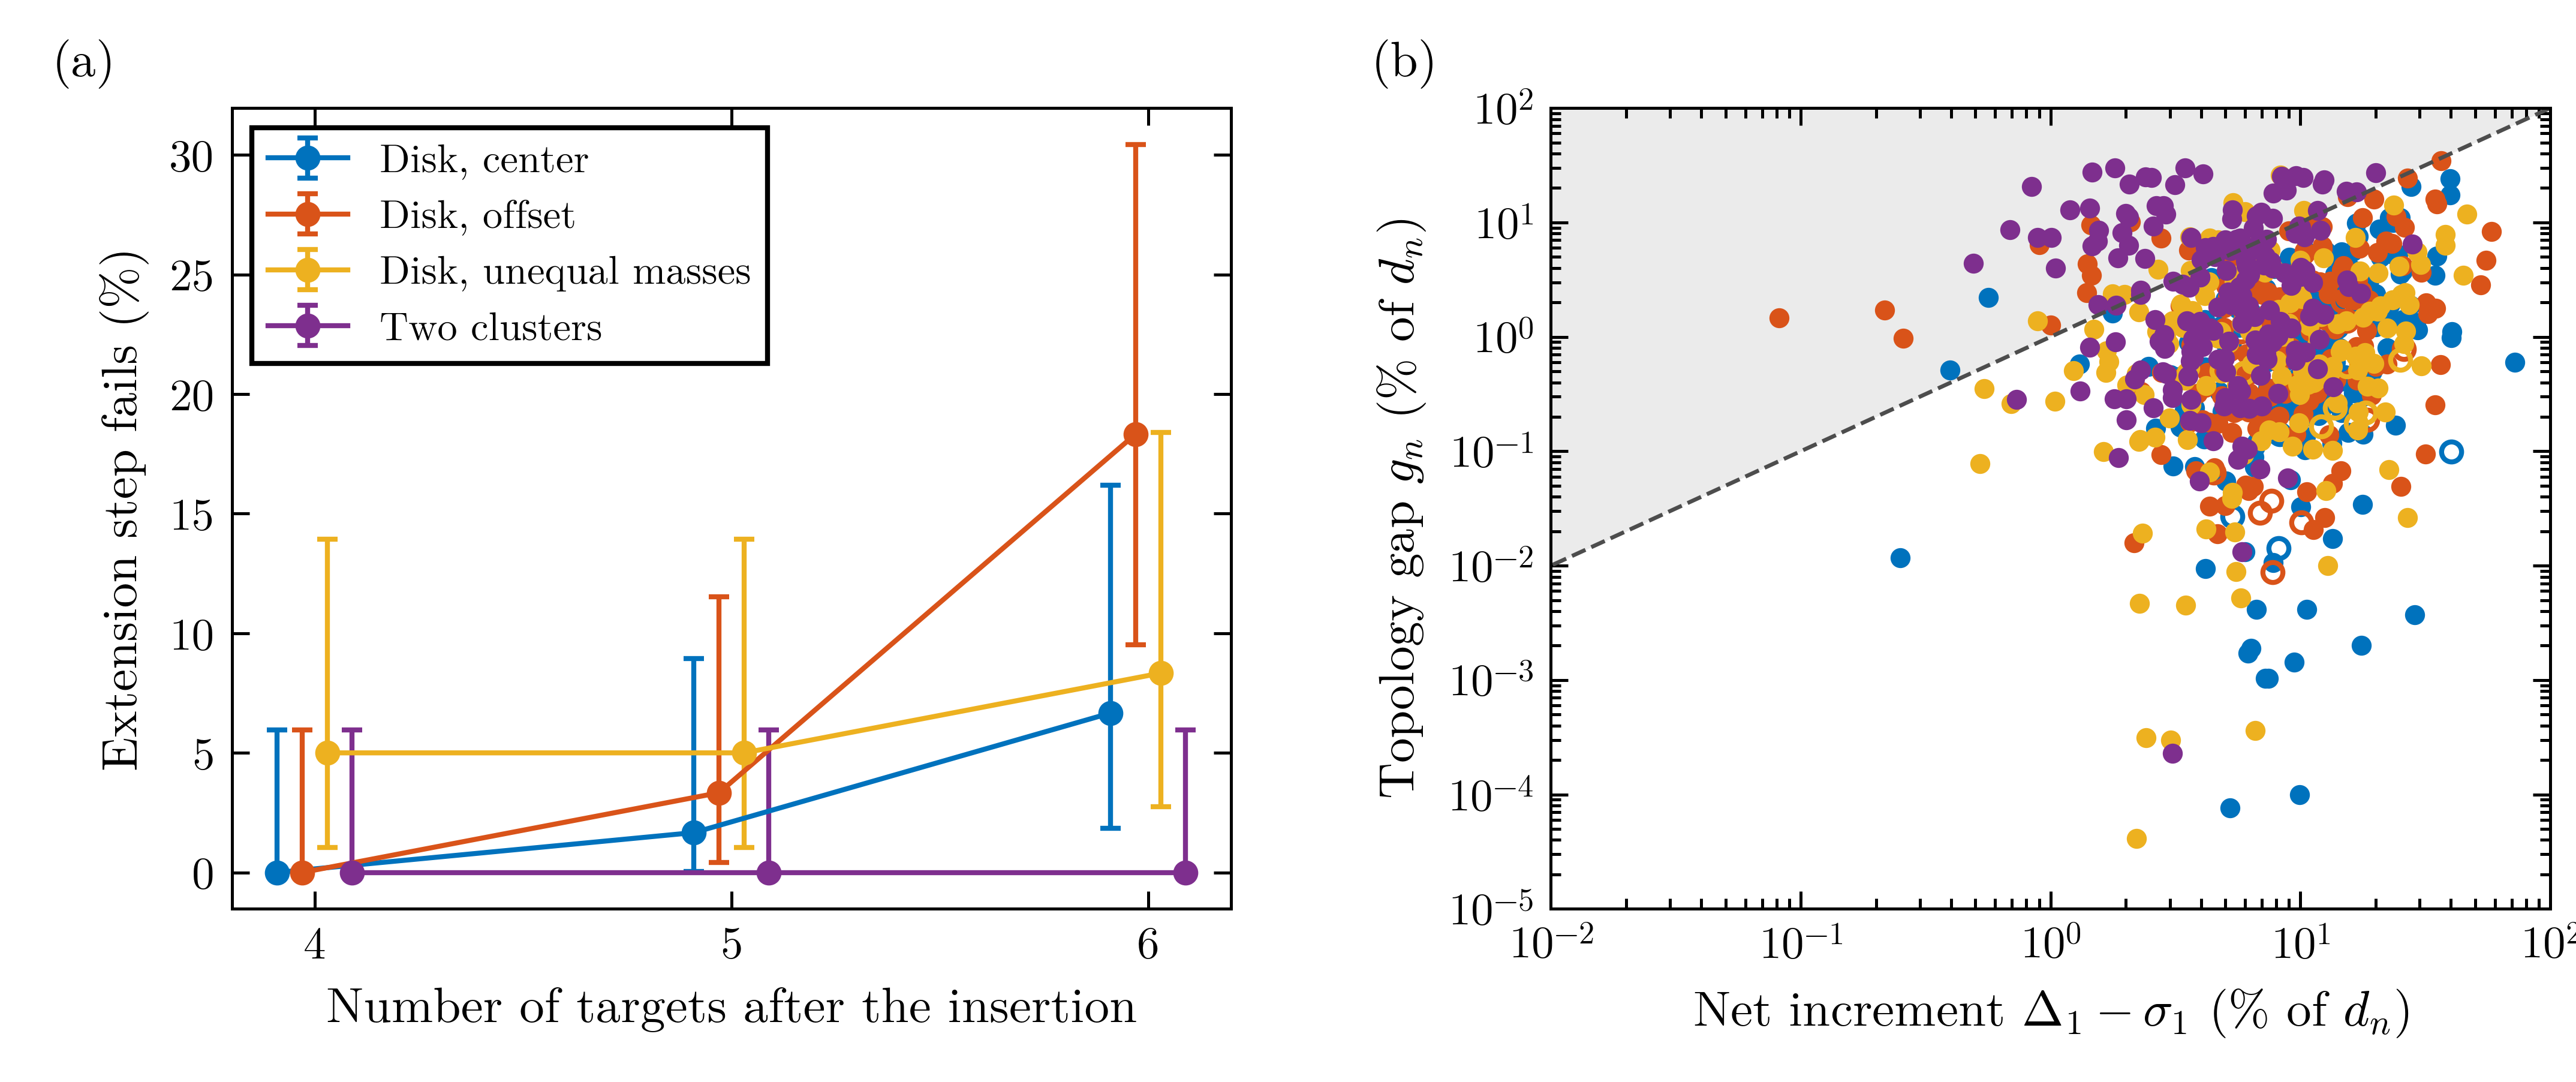

PNG identical to figures/replication/fig_replication.png: False (differences in fonts or library versions, as in Colab, change the bytes but not the content)


In [14]:
path = RT.figure_replication(ROWS, pooled, os.path.join(OUT, "figures"))
display(Image(path, width=900))
print("PNG identical to figures/replication/fig_replication.png:",
      filecmp.cmp(path, os.path.join(FIG, "replication", "fig_replication.png"), shallow=False),
      "(differences in fonts or library versions, as in Colab, change the bytes but not the content)")

## 6. Deterministic ladders (Section 5.2), Table 2, and Figure 5

Four deterministic ladders complement the random ones: Halton points in the unit disk with unit masses and the source at the center or at $(0.5,0)$, up to seven targets, and, with the source at $(0.5,0)$, the same points with masses drawn in $[0.5,2]$ and one two-cluster instance, up to six targets. Along each ladder `RT.disk_ladder` and `RT.hard_ladder` compute the exact tree with ties, the extension of the previous exact tree, the pure induction, and the hub model. The default run recomputes two ladders up to five targets in parallel.

In [15]:
specs = ([("disk", a, src, None) for src in ((0.0, 0.0), (0.5, 0.0)) for a in RT.ALPHAS]
         + [("hard", c, a, None) for c in ("disk-unequal-masses", "two-clusters-unit") for a in RT.ALPHAS]) if RUN_FULL \
    else [("disk", 0.5, (0.0, 0.0), 5), ("hard", "two-clusters-unit", 0.75, 5)]
t0 = time.perf_counter()
fresh = [r for rows in RT.pmap(RT.ladder_job, specs) for r in rows]

def stored_row(r):
    if "case" in r:
        return [x for x in HARD if (x["case"], x["alpha"], x["n"]) == (r["case"], r["alpha"], r["n"])][0]
    return [x for x in LADDER if (x["source"], x["alpha"], x["n"]) == (r["source"], r["alpha"], r["n"])][0]

bad = [msg for r in fresh for ok, msg in [RT.agrees(r, stored_row(r), rel=1e-9, atol=1e-9)] if not ok]
print(f"{len(specs)} ladders, {len(fresh)} rows, in {time.perf_counter() - t0:.0f} s")
ck(f"deterministic ladders: {len(fresh)} recomputed rows agree with the stored ones", not bad, "; ".join(bad[:3]))

2 ladders, 6 rows, in 57 s
PASS  deterministic ladders: 6 recomputed rows agree with the stored ones


Two statements of Section 5.2 are recomputed directly. With the offset source at $\alpha=0.85$ the optimal tree on three targets is a star at the source, realized by three full topologies; extending each of them alone shows that two reach at best a four-target tree 0.21 percent above the optimum, so the extension step must extend all of them. With unequal masses at $\alpha=0.5$ the failure is topological: the optimal five-target tree, restricted to the first four targets, has the split $\lbrace O,2,4\rbrace \mid\lbrace 1,3\rbrace $, while the optimal four-target tree has $\lbrace O,3\rbrace \mid\lbrace 1,2,4\rbrace $.

In [16]:
# every one of the three tied topologies of the three-target star, extended alone
s, T = np.array([0.5, 0.0]), RT.disk_points(7)
m, alpha = np.ones(7), 0.85
best, ties = RC.solve_exhaustive(RC.terminals_of(s, T[:3]), m[:3], alpha, return_ties=True)
d4 = stored_row({"source": [0.5, 0.0], "alpha": alpha, "n": 4})["exact"]
excess = sorted(100 * (RT.insert_best_edge_multi([tie], RC.terminals_of(s, T[:4]), m[:4], alpha)[0][0] / d4 - 1) for tie in ties)
print(f"{len(ties)} tied topologies on three targets; best extension of each alone: {np.round(excess, 3)} percent above d_4")
ck("Section 5.2: two of the three tied topologies extend to 0.21% above the optimum, the third reaches it",
   len(ties) == 3 and abs(excess[0]) < 1e-6 and [round(e, 2) for e in excess[1:]] == [0.21, 0.21])

# the splits of the optimal four-target tree and of the optimal five-target tree restricted to four targets
s, T, m, _ = DET["Disk, unequal masses"]
alpha = 0.5

def internal_splits(edges, nterm):
    """The targets below each internal edge (bitmask -> sorted target indices)."""
    full = (1 << nterm) - 2
    return sorted(sorted(i for i in range(1, nterm) if sp >> i & 1) for sp in RT.canon(edges, nterm)
                  if bin(sp).count("1") >= 2 and sp != full)

_, t4 = RC.solve_exhaustive(RC.terminals_of(s, T[:4]), m[:4], alpha, return_ties=True)
_, t5 = RC.solve_exhaustive(RC.terminals_of(s, T[:5]), m[:5], alpha, return_ties=True)
sp4 = internal_splits(t4[0][1].edges, 5)
sp5 = internal_splits(RT.restrict(t5[0][1].edges, 6, 5), 5)
print("optimal four-target tree, targets below its internal edges:", sp4)
print("optimal five-target tree restricted to four targets:", sp5)
ck("Section 5.2: {O,3}|{1,2,4} in the four-target tree, {O,2,4}|{1,3} in the restricted five-target tree",
   len(t4) == 1 and len(t5) == 1 and [1, 2, 4] in sp4 and [1, 3] in sp5 and [1, 3] not in sp4)

3 tied topologies on three targets; best extension of each alone: [0.    0.212 0.212] percent above d_4
PASS  Section 5.2: two of the three tied topologies extend to 0.21% above the optimum, the third reaches it
optimal four-target tree, targets below its internal edges: [[1, 2, 4], [2, 4]]
optimal five-target tree restricted to four targets: [[1, 3], [2, 4]]
PASS  Section 5.2: {O,3}|{1,2,4} in the four-target tree, {O,2,4}|{1,3} in the restricted five-target tree


Table 2 from the stored ladders, compared with `overleaf_A/tables/tab_ladder.tex`, the numbers of Section 5.2, and Figure 5.

In [17]:
text = RT.table_ladder(LADDER, HARD, os.path.join(OUT, "tables", "tab_ladder.tex"))
ok, msg = RT.compare_table(text, os.path.join(TABLES, "tab_ladder.tex"))
ck("Table 2 identical to overleaf_A/tables/tab_ladder.tex", ok, msg)
print(text)

get = lambda rows, **kw: [r for r in rows if all(r.get(k) == v for k, v in kw.items())]
une = sorted(get(HARD, case="disk-unequal-masses", alpha=0.5), key=lambda r: r["n"])
c75 = get(HARD, case="two-clusters-unit", alpha=0.75, n=6)[0]
c85 = get(HARD, case="two-clusters-unit", alpha=0.85, n=6)[0]
off05 = [r["hub_gap_pct"] for r in get(LADDER, source=[0.5, 0.0], alpha=0.5) if r["n"] >= 4]
cl05 = [r["hub_gap_pct"] for r in get(HARD, case="two-clusters-unit", alpha=0.5) if r["n"] >= 4]
ck("5.2: unit masses on the disk, extension optimal at every rung, at most three nondegenerate branching points, up to 15 ties",
   all(r.get("extension_is_optimal", True) for r in LADDER) and max(r["branching_points_nondegenerate"] for r in LADDER) == 3
   and max(r["optimal_topologies"] for r in LADDER + HARD) == 15)
ck("5.2: unequal masses at alpha = 0.5, pure induction 0.63 and 1.08% at n = 5, 6; extension at n = 6 misses by 1.14%",
   [round(r["pure_induction_gap_pct"], 2) for r in une[2:]] == [0.63, 1.08] and round(une[3]["greedy_from_exact_gap_pct"], 2) == 1.14)
ck("5.2: two clusters, extension fails at alpha = 0.75 at n = 6 by 0.06%; at 0.85 pure induction 0.0004% above, extension optimal",
   round(c75["greedy_from_exact_gap_pct"], 2) == 0.06 and round(c85["pure_induction_gap_pct"], 4) == 0.0004
   and c85["extension_is_optimal"])
ck("5.2: hub model 2.9-5.1% (offset, alpha = 0.5), 3.7-7.5% (clusters, alpha = 0.5), at most 0.16% with the source at the center",
   (round(min(off05), 1), round(max(off05), 1)) == (2.9, 5.1) and (round(min(cl05), 1), round(max(cl05), 1)) == (3.7, 7.5)
   and round(max(r["hub_gap_pct"] for r in LADDER if r["source"] == [0.0, 0.0]), 2) == 0.16)
ck("4.1: the extension of the previous optimal tree never beat the reference", not any(r.get("reference_beaten_by_extension")
                                                                                       for r in LADDER + HARD))

PASS  Table 2 identical to overleaf_A/tables/tab_ladder.tex  [identical]
\begin{tabular}{llrrrrr}
\toprule
Instance & $\alpha$ & $n$ & \begin{tabular}[b]{@{}c@{}}Branching\\points\end{tabular} & \begin{tabular}[b]{@{}c@{}}Optimal\\topologies\end{tabular} & \begin{tabular}[b]{@{}c@{}}Pure induction,\\excess (\%)\end{tabular} & \begin{tabular}[b]{@{}c@{}}Hub model,\\excess (\%)\end{tabular} \\
\midrule
Disk, center & 0.5 & 3 & 1 & 1 & -- & 0.000 \\
Disk, center & 0.5 & 4 & 2 & 1 & 0.000 & 0.000 \\
Disk, center & 0.5 & 5 & 2 & 3 & 0.000 & 0.000 \\
Disk, center & 0.5 & 6 & 1 & 9 & 0.000 & 0.000 \\
Disk, center & 0.5 & 7 & 2 & 9 & 0.000 & 0.000 \\
Disk, center & 0.75 & 3 & 1 & 1 & -- & 0.000 \\
Disk, center & 0.75 & 4 & 2 & 1 & 0.000 & 0.000 \\
Disk, center & 0.75 & 5 & 2 & 3 & 0.000 & 0.000 \\
Disk, center & 0.75 & 6 & 2 & 3 & 0.000 & 0.052 \\
Disk, center & 0.75 & 7 & 3 & 3 & 0.000 & 0.044 \\
Disk, center & 0.85 & 3 & 1 & 1 & -- & 0.000 \\
Disk, center & 0.85 & 4 & 2 & 1 & 0.000 & 0.000 \

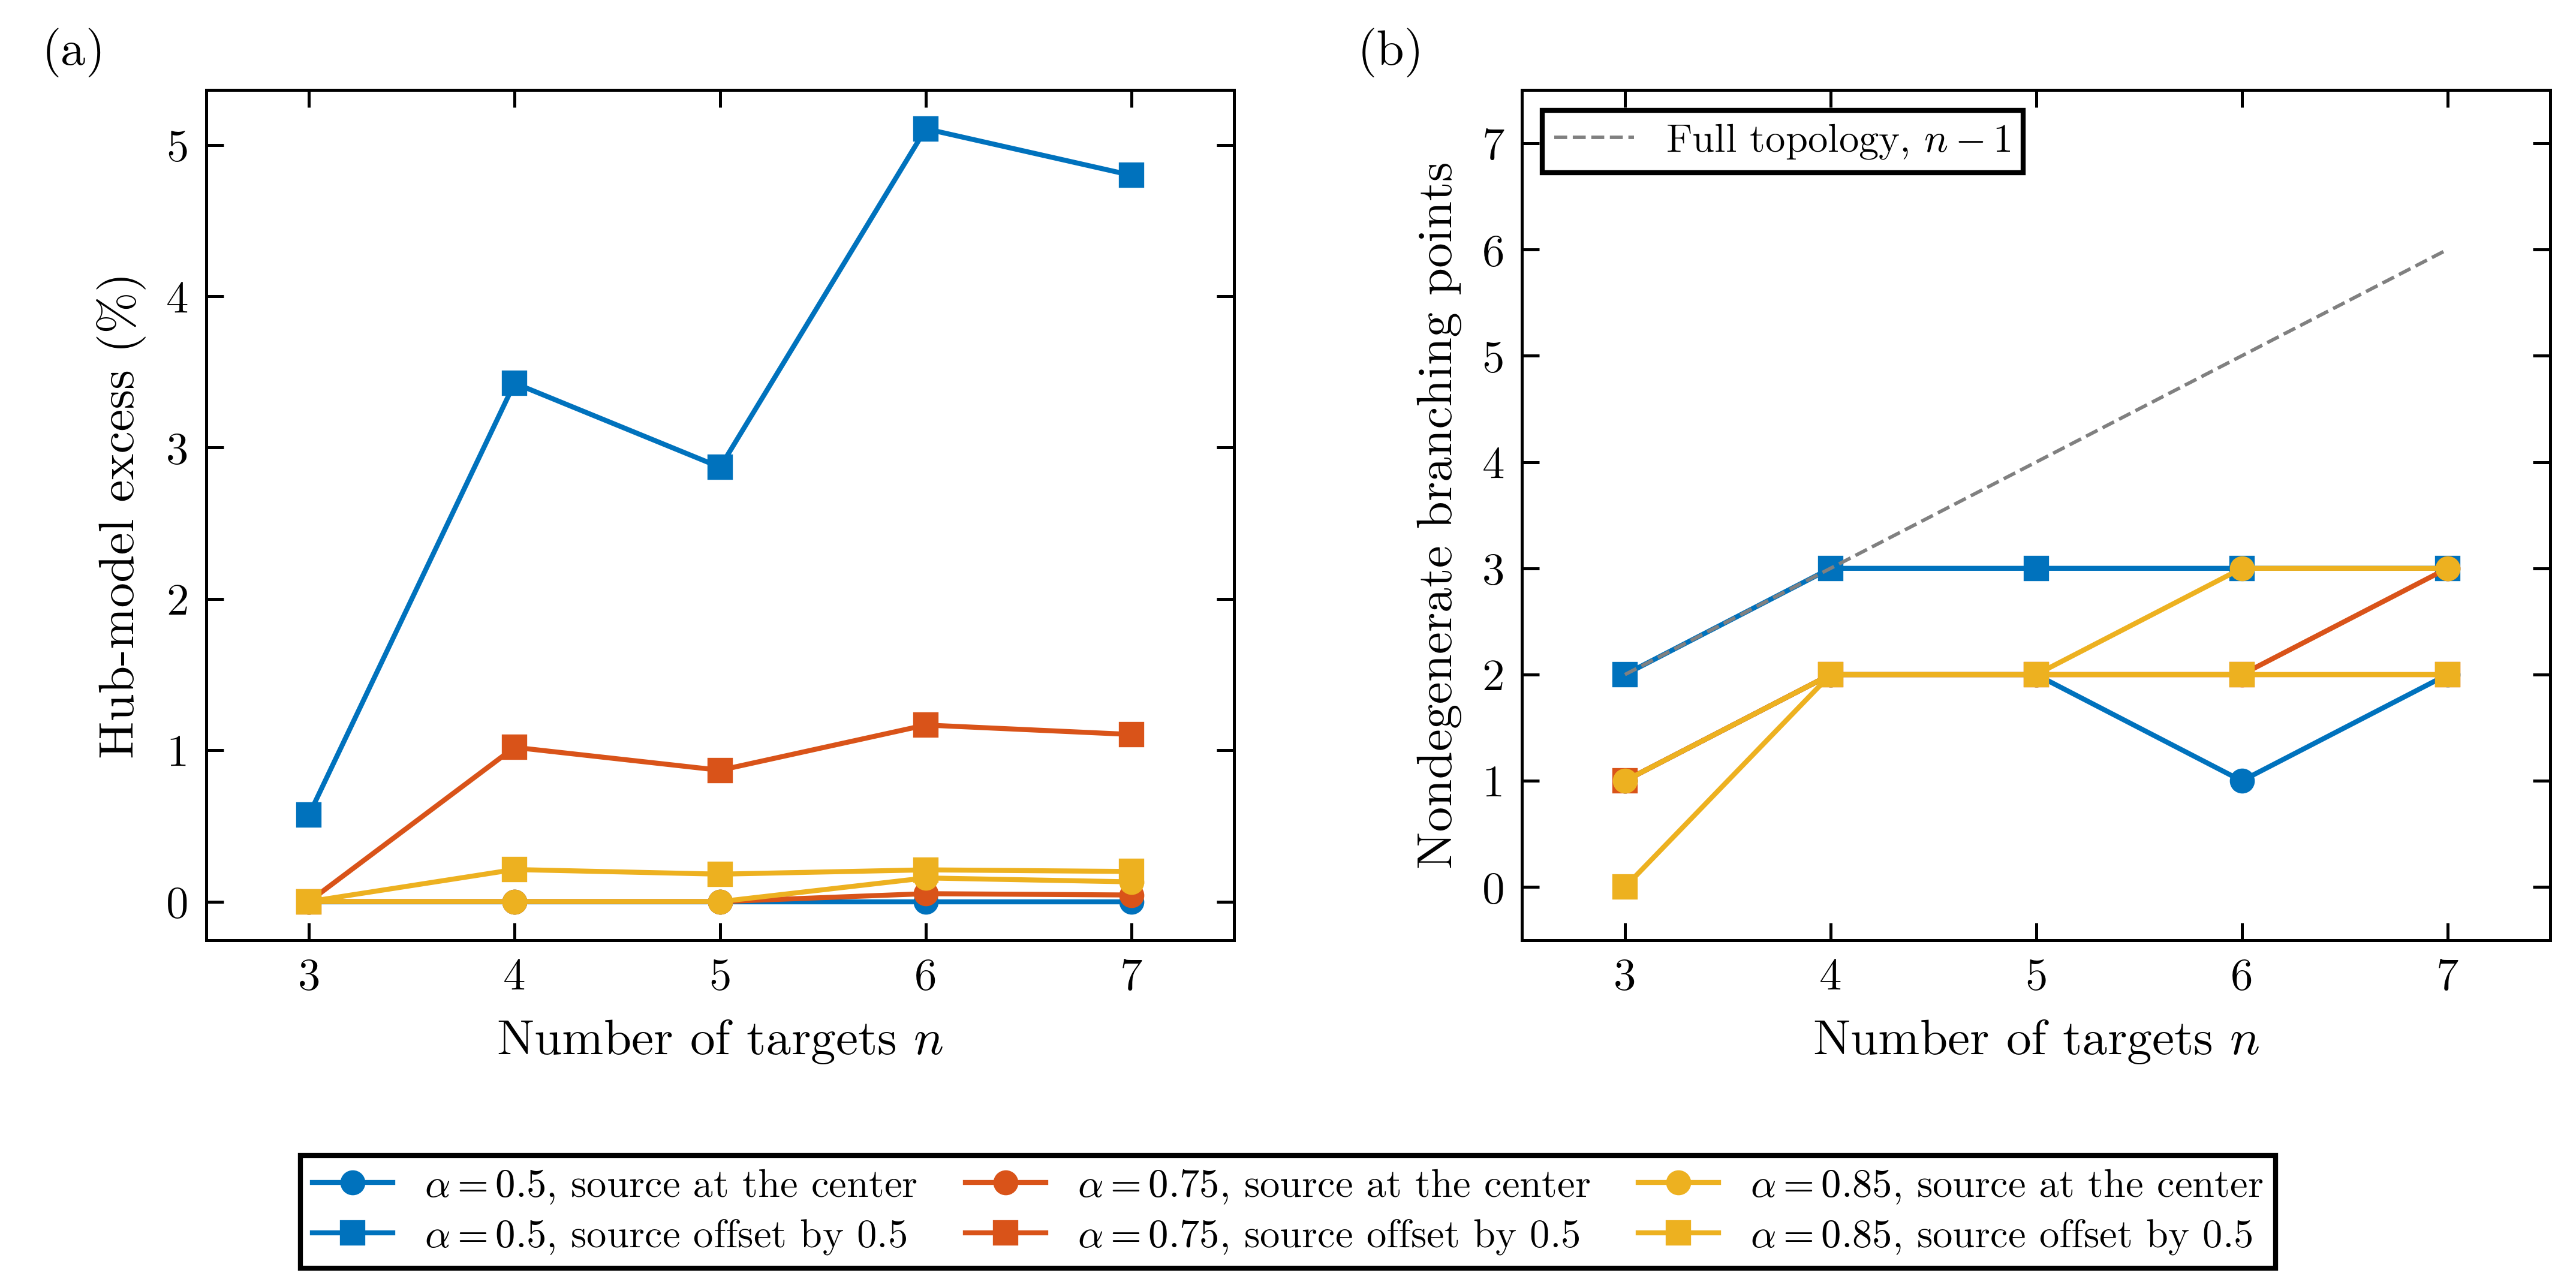

PNG identical to figures/inductive/fig_inductive_ladder.png: False (differences in fonts or library versions, as in Colab, change the bytes but not the content)


In [18]:
path = RT.figure_inductive_ladder(LADDER, os.path.join(OUT, "figures"))
display(Image(path, width=900))
print("PNG identical to figures/inductive/fig_inductive_ladder.png:",
      filecmp.cmp(path, os.path.join(FIG, "inductive", "fig_inductive_ladder.png"), shallow=False),
      "(differences in fonts or library versions, as in Colab, change the bytes but not the content)")

## 7. Batch insertion (Section 4.2, Propositions 3.9 and 3.10, Section 5.4) and Table 4

**Definition 3.8.** Let $T$ be a full topology on $k$ terminals, realized with branching points $P$, and let $y_{n+1},\dots,y_{n+b}$ be new targets. A choice map $\varphi$ assigns to each new target an edge of $T$; its insertion replaces every edge $e=(u,v)$ by a path from $u$ to $v$ with one new branching point for each $y_j$ with $\varphi(j)=e$, joined to $y_j$ and ordered along the path as the projections of the targets on the line through $P_u$ and $P_v$. The reach $R_b(T)$ is the set of insertions of all choice maps; a chain extension hangs every new target by its own branching point from the path that replaces an edge of $T$, and $C_b(T)$ is the set of chain extensions.

**Proposition 3.9.** With $E=2k-3$, the map from choice maps to insertions is injective and

$$R_b(T)\subseteq C_b(T)\subseteq\operatorname{Ext}_b(T),\qquad |R_b(T)|=E^{b},\quad |C_b(T)|=\prod_{i=0}^{b-1}(E+i),\quad |\operatorname{Ext}_b(T)|=\prod_{i=0}^{b-1}(E+2i).$$

**Proposition 3.10.** If no edge of the realization of $T$ has length zero, the insertions of the choice maps, as the new targets range over the plane, are exactly the chain extensions.

For $b=2$ the $2E$ extensions outside the reach are, on each edge, the two new targets joined first (a cherry) and the chain in the order opposite to the projections. The joint insertion enumerates the reach $R_b(T)$, the feasible set of the one-hot program

$$Q(x)=\sum_{j,e}c_{je}\,x_{je}+\sum_{j<j'}\sum_e\beta_{jj'e}\,x_{je}x_{j'e},\qquad \sum_e x_{je}=1\ \text{for every } j,$$

and a window of $\omega$ targets detaches the $\omega$ most recent targets and inserts them again with the new ones on the reduced tree.

The check of Appendix A builds $\operatorname{Ext}_b(T)$ by insertion and by restriction, counts the chain extensions, maps every choice map for six random placements of the branching points and of the new targets, and places the targets as in the proof of Proposition 3.10 to reach every chain extension. The default run covers $k=4,5$ and $b=1,2$; `RUN_FULL` adds $k=6$ and $b=3$ (about three minutes).

In [19]:
cases = [(k, b) for k in (4, 5, 6) for b in (1, 2, 3)] if RUN_FULL else [(k, b) for k in (4, 5) for b in (1, 2)]
t0 = time.perf_counter()
for k, b in cases:
    res = RT.reach_check(k, b)                 # topologies only: no geometry is optimized here
    keys = ("ext_agree", "ext_count_ok", "chain_count_ok", "injective", "image_in_chain", "coverage")
    print(f"k = {res['k']}, b = {res['b']}: {res['topologies']} topologies, |R| = {res['R']}, |C| = {res['C']}, "
          f"|Ext| = {res['Ext']}, missing from the reach {res['Ext'] - res['R']}; checks {[res[k_] for k_ in keys]}")
    E = 2 * res["k"] - 3
    missing = {1: 0, 2: 2 * E, 3: 6 * E ** 2 + 8 * E}[res["b"]]
    ck(f"Propositions 3.9 and 3.10, k = {res['k']}, b = {res['b']}", all(res[k_] for k_ in keys) and res["Ext"] - res["R"] == missing)
print(f"{time.perf_counter() - t0:.0f} s")

k = 4, b = 1: 3 topologies, |R| = 5, |C| = 5, |Ext| = 5, missing from the reach 0; checks [True, True, True, True, True, True]
PASS  Propositions 3.9 and 3.10, k = 4, b = 1
k = 4, b = 2: 3 topologies, |R| = 25, |C| = 30, |Ext| = 35, missing from the reach 10; checks [True, True, True, True, True, True]
PASS  Propositions 3.9 and 3.10, k = 4, b = 2
k = 5, b = 1: 15 topologies, |R| = 7, |C| = 7, |Ext| = 7, missing from the reach 0; checks [True, True, True, True, True, True]
PASS  Propositions 3.9 and 3.10, k = 5, b = 1
k = 5, b = 2: 15 topologies, |R| = 49, |C| = 56, |Ext| = 63, missing from the reach 14; checks [True, True, True, True, True, True]
PASS  Propositions 3.9 and 3.10, k = 5, b = 2
1 s


The batch ladder of Table 4: from the exact three-target tree, two targets at a time, each column continuing from the tree that the same step produced at the previous step. `RT.batch_ladder` runs the sequential induction and the joint insertion with window $\omega$; the default run recomputes the step from three to five targets with $\omega=0$ and $1$ on both instances and compares it with the stored rows (`figures/inductive/*/summary.csv`).

In [20]:
import pandas as pd

FOLDERS = {("disk-unequal", 0): "disk-unequal-a050", ("disk-unequal", 1): "disk-unequal-a050-w1",
           ("disk-unequal", 2): "disk-unequal-a050-w2", ("two-clusters", 0): "clusters-a075",
           ("two-clusters", 1): "clusters-a075-w1", ("two-clusters", 2): "clusters-a075-w2"}
ALPHA = {"disk-unequal": 0.5, "two-clusters": 0.75}
specs = [(inst, ALPHA[inst], w, None if RUN_FULL else 5) for inst in ALPHA for w in ((0, 1, 2) if RUN_FULL else (0, 1))]
t0 = time.perf_counter()
results = RT.pmap(RT.batch_job, specs)
bad, n_rows = [], 0
for (inst, alpha, w, _), rows in zip(specs, results):
    stored = pd.read_csv(os.path.join(FIG, "inductive", FOLDERS[(inst, w)], "summary.csv"))
    for r in rows:
        st = stored[(stored.method == r["method"]) & (stored.n_before == r["n_before"]) & (stored.run == 0)].iloc[0]
        n_rows += 1
        ok = abs(r["cost"] - st.cost) <= 1e-9 * st.cost and r["evaluations"] == st.evaluations
        if not np.isnan(st.exact):
            ok &= abs(r["exact"] - st.exact) <= 1e-9 * st.exact and abs(r["gap_pct"] - st.gap_pct) <= 1e-6
        if not ok:
            bad.append(f"{inst} w = {w} {r['method']} n = {r['n_before']}")
        print(f"{inst:12s} alpha = {alpha} w = {w} {r['n_before']} -> {r['n_after']} {r['method']:>10}: "
              f"excess {r['gap_pct']:.4f}% (stored {st.gap_pct:.4f}%)")
print(f"{time.perf_counter() - t0:.0f} s")
ck(f"batch insertion: {n_rows} recomputed steps agree with the stored rows", not bad, f"{bad}" if bad else "")

disk-unequal alpha = 0.5 w = 0 3 -> 5 sequential: excess 0.6296% (stored 0.6296%)
disk-unequal alpha = 0.5 w = 0 3 -> 5      joint: excess 0.6296% (stored 0.6296%)
disk-unequal alpha = 0.5 w = 1 3 -> 5 sequential: excess 0.6296% (stored 0.6296%)
disk-unequal alpha = 0.5 w = 1 3 -> 5      joint: excess 0.0000% (stored 0.0000%)
two-clusters alpha = 0.75 w = 0 3 -> 5 sequential: excess 0.0000% (stored 0.0000%)
two-clusters alpha = 0.75 w = 0 3 -> 5      joint: excess 0.0000% (stored 0.0000%)
two-clusters alpha = 0.75 w = 1 3 -> 5 sequential: excess 0.0000% (stored 0.0000%)
two-clusters alpha = 0.75 w = 1 3 -> 5      joint: excess 0.0000% (stored 0.0000%)
73 s
PASS  batch insertion: 8 recomputed steps agree with the stored rows


In [21]:
text = RT.table_batch(FIG, os.path.join(OUT, "tables", "tab_batch_without_application.tex"))
ok, msg = RT.compare_table(text, os.path.join(TABLES, "tab_batch.tex"), data_rows_only=True)
ck("Table 4: every row outside the application as published", ok, msg)
print(text)
rows, _ = RT.batch_rows(FIG)
cell = {(r["instance"], r["rung"]): r for r in rows}
u35, u57, c57 = cell[("disk-unequal", "3->5")], cell[("disk-unequal", "5->7")], cell[("two-clusters", "5->7")]
ck("5.4: unequal-mass disk 3 -> 5, sequential and joint without window 0.630% above, the window of one reaches the optimum",
   round(u35["sequential"], 3) == 0.630 and u35["joint"][:2] == ["0.630", "0.000"])
ck("5.4: unequal-mass disk 5 -> 7, the window of one ends 1.09% above, the window of two reaches the optimum",
   u57["joint"][1] == "1.092" and u57["joint"][2] == "0.000")
ck("5.4: two clusters 5 -> 7, every step misses by 0.006%", round(c57["sequential"], 3) == 0.006 and c57["joint"] == ["0.006"] * 3)

PASS  Table 4: every row outside the application as published  [all 12 lines found in order]
\begin{tabular}{lrlrrrr}
\toprule
 & & & & \multicolumn{3}{c}{Joint, $\omega=$} \\
\cmidrule(lr){5-7}
Instance & $\alpha$ & Step & Sequential & 0 & 1 & 2 \\
\midrule
Disk, unequal masses & 0.5 & $3\to5$ & 0.630 & 0.630 & 0.000 & -- \\
Disk, unequal masses & 0.5 & $5\to7$ & 1.034 & 1.034 & 1.092 & 0.000 \\
Two clusters & 0.75 & $3\to5$ & 0.000 & 0.000 & 0.000 & -- \\
Two clusters & 0.75 & $5\to7$ & 0.006 & 0.006 & 0.006 & 0.006 \\
\bottomrule
\end{tabular}

PASS  5.4: unequal-mass disk 3 -> 5, sequential and joint without window 0.630% above, the window of one reaches the optimum
PASS  5.4: unequal-mass disk 5 -> 7, the window of one ends 1.09% above, the window of two reaches the optimum
PASS  5.4: two clusters 5 -> 7, every step misses by 0.006%


Why the steps fail where they fail (Appendix A, *Restriction of the optimal topologies*): for each two-target step, the optimal topologies of both instances with ties, the extension property, the best cost over every extension of the optimal topologies of the smaller instance, and whether the restrictions to $n-1$ and $n-2$ targets agree, which is what windows of one and two targets need. The default run recomputes the two steps from three to five targets; `RUN_FULL` adds the steps from five to seven (eight terminals, several minutes each).

In [22]:
stored = {(r["instance"], r["alpha"], r["n"]): r for r in load("inductive", "restriction_check_v2.json")}
cases = [("disk-unequal", 0.5, 3, 2), ("two-clusters", 0.75, 3, 2)]
if RUN_FULL:
    cases += [("disk-unequal", 0.5, 5, 2), ("two-clusters", 0.75, 5, 2)]
t0 = time.perf_counter()
fresh = RT.pmap(RT.restriction_case, cases)
for r in fresh:
    ok, msg = RT.agrees(r, stored[(r["instance"], r["alpha"], r["n"])], rel=1e-9, atol=1e-9)
    ck(f"restriction check, {r['instance']} {r['n']} -> {r['n'] + 2}: as stored", ok, msg)
print(f"{time.perf_counter() - t0:.0f} s")
du3, du5 = stored[("disk-unequal", 0.5, 3)], stored[("disk-unequal", 0.5, 5)]
tc5 = stored[("two-clusters", 0.75, 5)]
ck("Appendix A: unequal-mass disk 3 -> 5 has no optimal extension; best over all extensions 0.63% above",
   not du3["extension_property_holds"] and round(du3["best_over_all_extensions_gap_pct"], 2) == 0.63)
ck("Appendix A: unequal-mass disk 5 -> 7, best extension 1.09% above; no restriction to four or three targets agrees",
   round(du5["best_over_all_extensions_gap_pct"], 2) == 1.09
   and not du5["windows"]["1"]["large_and_small_agree"] and not du5["windows"]["2"]["large_and_small_agree"])
ck("Appendix A: two clusters 5 -> 7, best over all extensions 0.0062% above; the optimum restricts to the optimal three-target tree",
   round(tc5["best_over_all_extensions_gap_pct"], 4) == 0.0062 and tc5["windows"]["2"]["large_restricts_to_optimal"])

PASS  restriction check, disk-unequal 3 -> 5: as stored
PASS  restriction check, two-clusters 3 -> 5: as stored
49 s
PASS  Appendix A: unequal-mass disk 3 -> 5 has no optimal extension; best over all extensions 0.63% above
PASS  Appendix A: unequal-mass disk 5 -> 7, best extension 1.09% above; no restriction to four or three targets agrees
PASS  Appendix A: two clusters 5 -> 7, best over all extensions 0.0062% above; the optimum restricts to the optimal three-target tree


On the replicated ladders (Section 5.4) the two-target steps from three and from four targets show how often each obstacle occurs, and `RT.cherry_case` classifies the best two-target extension of every step where the joint insertion over the reach misses: *cherry* (the two new targets joined first), *reversed chain*, *chain*, or *separate*. The default run recomputes six of the 96 misses.

In [23]:
two = [r for r in ROWS if "batch_extension_property" in r]
disk2 = [r for r in two if r["family"] != "clusters"]
ext_fail = [r for r in disk2 if not r["batch_extension_property"]]
from_four = [r for r in ext_fail if r["n"] == 4]
joint_miss = [r for r in disk2 if r["batch_joint_reach_gap_rel"] > RT.TIE]
print(f"{len(disk2)} disk steps; extension property fails on {len(ext_fail)} ({len(from_four)} from four targets, "
      f"window of one possible on {sum(r['batch_window_agree'].get('1', False) for r in from_four)}); joint misses "
      f"{len(joint_miss)} (up to {100 * max(r['batch_joint_reach_gap_rel'] for r in joint_miss):.1f}%), "
      f"{sum(r['batch_extension_property'] for r in joint_miss)} with the extension property; sequential misses "
      f"{sum(r['batch_sequential_gap_rel'] > RT.TIE for r in disk2)}")
ck("5.4: 360 disk steps, extension property fails on 18, 13 from four targets, window of one possible on 9",
   len(disk2) == 360 and len(ext_fail) == 18 and len(from_four) == 13
   and sum(r["batch_window_agree"].get("1", False) for r in from_four) == 9)
ck("5.4: joint insertion misses on 96 steps, by up to 13%, 78 with the extension property; sequential misses on 26",
   len(joint_miss) == 96 and round(100 * max(r["batch_joint_reach_gap_rel"] for r in joint_miss)) == 13
   and sum(r["batch_extension_property"] for r in joint_miss) == 78 and sum(r["batch_sequential_gap_rel"] > RT.TIE for r in disk2) == 26)
ck("5.4: no step of either kind misses on the cluster family",
   not any(r["batch_joint_reach_gap_rel"] > RT.TIE or r["batch_sequential_gap_rel"] > RT.TIE for r in two if r["family"] == "clusters"))

CHERRY = load("replication", "cherry_check.json")
from collections import Counter
kinds = Counter(c["best_extension_kind"] for c in CHERRY if c["best_extension_gap_rel"] <= RT.TIE)
print("best extension of the misses with the extension property:", dict(kinds))
ck("5.4: of the 78, the best extension joins the new targets first in 66 and is the reversed chain in 12",
   len(CHERRY) == 96 and kinds == {"cherry": 66, "reversed chain": 12})

cases = joint_miss if RUN_FULL else [r for r in joint_miss if r["n"] == 3][:6]
t0 = time.perf_counter()
fresh = RT.pmap(RT.cherry_case, cases)
key = lambda c: (c["family"], c["seed"], c["alpha"], c["n"])
stored_c = {key(c): c for c in CHERRY}
bad = [key(c) for c in fresh if not RT.agrees(c, stored_c[key(c)], rel=1e-7, atol=1e-9)[0]]
print(f"{len(fresh)} misses classified in {time.perf_counter() - t0:.0f} s")
ck(f"cherry check: {len(fresh)} recomputed classifications as stored", not bad, f"{bad}" if bad else "")

360 disk steps; extension property fails on 18 (13 from four targets, window of one possible on 9); joint misses 96 (up to 12.8%), 78 with the extension property; sequential misses 26
PASS  5.4: 360 disk steps, extension property fails on 18, 13 from four targets, window of one possible on 9
PASS  5.4: joint insertion misses on 96 steps, by up to 13%, 78 with the extension property; sequential misses on 26
PASS  5.4: no step of either kind misses on the cluster family
best extension of the misses with the extension property: {'cherry': 66, 'reversed chain': 12}
PASS  5.4: of the 78, the best extension joins the new targets first in 66 and is the reversed chain in 12
6 misses classified in 35 s
PASS  cherry check: 6 recomputed classifications as stored


## 8. Eight-terminal references (Section 4.1)

Above 1000 topologies the exact solver polishes the topologies within 25 percent of the best scan cost, at most 5000. At eight terminals between 2312 and all 10 395 topologies of the instances of the paper lie within that margin, so the cap decides the selection in five of the eight instances; all eight references were therefore recomputed with every topology polished, and they agree with the capped polish to $10^{-15}$ relative. The stored results are in `figures/replication/full_polish_8.json` and `scan_margin_8.json`; `RUN_FULL` recomputes both (about two minutes per case for the margins and about 20 minutes per case for the full polish).

In [24]:
fp = load("replication", "full_polish_8.json")
sm = load("replication", "scan_margin_8.json")
for r in sorted(fp, key=lambda r: (r["case"], r["alpha"])):
    w = [x for x in sm if (x["case"], x["alpha"]) == (r["case"], r["alpha"])][0]
    print(f"{r['case']:20s} alpha = {r['alpha']:<5} within 25%: {w['within_rho']:5d} of 10395; "
          f"full polish against stored {r['rel_diff']:+.1e}; {r['n_optimal']} optimal topologies")
ck("4.1: 2312 to 10395 topologies within the margin; the cap binds in 5 of 8; full polish agrees to 1e-15",
   (min(x["within_rho"] for x in sm), max(x["within_rho"] for x in sm)) == (2312, 10395)
   and sum(x["within_rho"] > 5000 for x in sm) == 5 and len(fp) == 8 and max(abs(r["rel_diff"]) for r in fp) <= 1e-15)
if RUN_FULL:
    cases = [(r["case"], r["alpha"]) for r in sm]
    for r in RT.pmap(RT.eight_terminal_scan_margin, cases):
        old = [x for x in sm if (x["case"], x["alpha"]) == (r["case"], r["alpha"])][0]
        ck(f"scan margin {r['case']} alpha = {r['alpha']}", r["within_rho"] == old["within_rho"])
    for r in RT.pmap(RT.eight_terminal_full_polish, [(r["case"], r["alpha"], r["stored"]) for r in fp]):
        ck(f"full polish {r['case']} alpha = {r['alpha']}", abs(r["rel_diff"]) <= 1e-12, f"{r['rel_diff']:+.1e}")

clusters-5to7        alpha = 0.75  within 25%:  2312 of 10395; full polish against stored +0.0e+00; 1 optimal topologies
disk-ladder-center   alpha = 0.5   within 25%: 10395 of 10395; full polish against stored +0.0e+00; 9 optimal topologies
disk-ladder-center   alpha = 0.75  within 25%: 10395 of 10395; full polish against stored +0.0e+00; 3 optimal topologies
disk-ladder-center   alpha = 0.85  within 25%: 10395 of 10395; full polish against stored +2.2e-16; 15 optimal topologies
disk-ladder-offset   alpha = 0.5   within 25%:  6728 of 10395; full polish against stored -2.2e-16; 3 optimal topologies
disk-ladder-offset   alpha = 0.75  within 25%:  3396 of 10395; full polish against stored +2.2e-16; 15 optimal topologies
disk-ladder-offset   alpha = 0.85  within 25%:  2754 of 10395; full polish against stored +0.0e+00; 15 optimal topologies
disk-unequal-5to7    alpha = 0.5   within 25%: 10395 of 10395; full polish against stored +0.0e+00; 3 optimal topologies
PASS  4.1: 2312 to 10395 topo

## 9. Summary

Every check of this notebook, and the time it took. The rebuilt tables are in `colab/output/tables` and the figures in `colab/output/figures`.

In [25]:
all_passed = ck.summary()
print(f"notebook 2 ran in {(time.perf_counter() - T_START) / 60:.1f} minutes (RUN_FULL = {RUN_FULL})")
print("PASS" if all_passed else "FAIL")

63 of 63 checks passed
notebook 2 ran in 8.8 minutes (RUN_FULL = False)
PASS
